In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-darkgrid')

df = pd.read_csv('../data/processed/clean_daylight_data.csv', parse_dates=['timestamp'])

df = df.sort_values('timestamp').reset_index(drop=True)


In [4]:
df_faulty = df.copy()

#let us assume partial shading

# Creating a true/false mask for our shading timeframe
shade_mask = (df_faulty['timestamp'].dt.hour == 8) | \
             ((df_faulty['timestamp'].dt.hour == 9) & (df_faulty['timestamp'].dt.minute <= 30))

# Applying a 30% voltage drop
df_faulty.loc[shade_mask, 'v_dc'] = df_faulty.loc[shade_mask, 'v_dc'] * 0.70


# let us inject uniform dust now

# trying to check how many total days have passed since the first row
start_date = df_faulty['timestamp'].min()
df_faulty['days_elapsed'] = (df_faulty['timestamp'] - start_date).dt.days

# Using % to create a repeating 30 days loop (0 to 29)
df_faulty['dust_cycle_day'] = df_faulty['days_elapsed'] % 30

# Calculating the current multiplier. something like Day 0 = 1.0, Day 10 = 0.95, Day 29 = 0.855
df_faulty['dust_multiplier'] = 1 - (df_faulty['dust_cycle_day'] * 0.005)

df_faulty['i_dc'] = df_faulty['i_dc'] * df_faulty['dust_multiplier']

# grounf truth
df_faulty['label'] = 'Normal'

df_faulty.loc[shade_mask, 'label'] = 'Shaded'

df_faulty.loc[df_faulty['dust_cycle_day'] >= 20, 'label'] = 'Dusty'

overlap_mask = shade_mask & (df_faulty['dust_cycle_day'] >= 20)
df_faulty.loc[overlap_mask, 'label'] = 'Shaded_and_Dusty'

print("\nFinal Dataset Label Breakdown:")
print(df_faulty['label'].value_counts())


Final Dataset Label Breakdown:
label
Normal              476162
Dusty               241584
Shaded               79263
Shaded_and_Dusty     40045
Name: count, dtype: int64


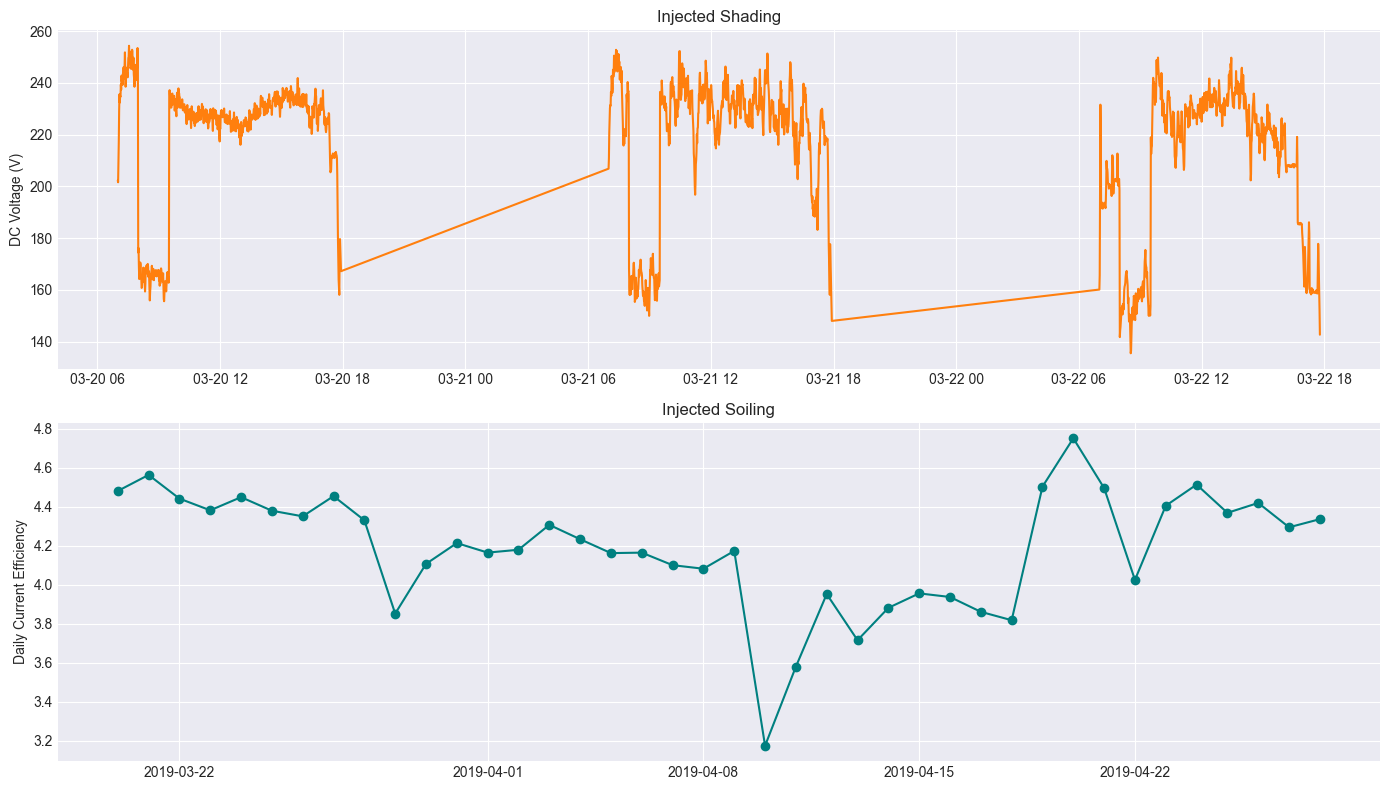

In [6]:
start_date = df_faulty['timestamp'].min()
three_days = df_faulty[(df_faulty['timestamp'] >= start_date) & 
                       (df_faulty['timestamp'] < start_date + pd.Timedelta(days=3))]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

ax1.plot(three_days['timestamp'], three_days['v_dc'], color='tab:orange')
ax1.set_title('Injected Shading')
ax1.set_ylabel('DC Voltage (V)')

df_faulty['current_efficiency'] = (df_faulty['i_dc'] / df_faulty['irradiance']) * 1000
daily_eff_faulty = df_faulty.set_index('timestamp').resample('D')['current_efficiency'].median().dropna()

# Plottig 40 days to see at least one full 30-day cycle reset
ax2.plot(daily_eff_faulty.head(40).index, daily_eff_faulty.head(40).values, marker='o', color='teal')
ax2.set_title('Injected Soiling')
ax2.set_ylabel('Daily Current Efficiency')

plt.tight_layout()
plt.show()

In [7]:
cols_to_drop = ['days_elapsed', 'dust_cycle_day', 'dust_multiplier', 'current_efficiency']
df_final = df_faulty.drop(columns=cols_to_drop, errors='ignore')

labeled_path = '../data/processed/labeled_fault_data.csv'

df_final.to_csv(labeled_path, index=False)
